In [11]:
import gymnasium as gym
from stable_baselines3 import PPO
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

# wind turbine environment

In [12]:


import gymnasium as gym
from gymnasium import spaces

import numpy as np


class WindTurbineEnv(gym.Env):
    """
    Wind turbine digital twin environment
    RL controls yaw velocity
    timestep:
        dt = 1 second
    """

    def __init__(self):
        super().__init__()
        # -------------------------
        # Simulation parameters
        # -------------------------

        self.dt = 1.0     # seconds

        # Turbine parameters
        self.rho = 1.225        # air density
        self.radius = 40        # rotor radius
        self.area = np.pi*self.radius**2

        self.Cp = 0.42          # power coefficient

        # yaw actuator
        self.max_yaw_speed = 1.0  # deg/sec
        
        # Observation space      
        # [wind speed,wind direction,yaw angle,yaw error,power]

        low=np.array([3,0,0,-180,0],dtype=np.float32)

        high=np.array([20,360,360,180,10e6],dtype=np.float32)

        self.observation_space = spaces.Box(low,high,dtype=np.float32)
        
        # Action      

        # yaw velocity command
        #
        # -1 deg/s to +1 deg/s

        self.action_space = spaces.Box(
            low=np.array([-1]),
            high=np.array([1]),
            dtype=np.float32
        )
        self.reset()
    

    def reset(self,seed=None,options=None):
        super().reset(seed=seed)
        self.time=0
        self.wind_speed=np.random.uniform(5,12)

        self.wind_direction=np.random.uniform(0,360)

        self.yaw=np.random.uniform(0,360)

        self.power=0
        obs=self.get_state()
        return obs,{}

    

    def wind_model(self):
        """
        Wind simulator
        speed:
        3-20 m/s
        direction:
        0-360 deg
        """
        self.wind_speed = (10+5*np.sin(0.002*self.time)+np.random.normal(0,0.2))

        self.wind_speed=np.clip(self.wind_speed,3,20)

        self.wind_direction += (0.5*np.sin(0.01*self.time)+np.random.normal(0,1))

        self.wind_direction %=360

    def turbine_power(self):
        yaw_error = (self.wind_direction-self.yaw)

        # convert to -180 to 180
        yaw_error = (yaw_error+180)%360-180

        yaw_rad=np.deg2rad(yaw_error)

        alignment = max(np.cos(yaw_rad), 0.0)

        # Power equation
        power=(0.5*self.rho*self.area*self.Cp*self.wind_speed**3*alignment**1.88)

        return max(power,0)


    def get_state(self):

        error=(self.wind_direction-self.yaw)
        error=(error+180)%360-180

        return np.array([self.wind_speed,self.wind_direction,self.yaw,error,self.power/1e6],dtype=np.float32)


    def step(self,action):
        self.time += self.dt

        # yaw actuator    
        yaw_velocity=float(action[0])
        self.yaw += (yaw_velocity*self.dt)
        self.yaw %=360
       
        # wind update      
        self.wind_model()
       
        # power generation       
        self.power=self.turbine_power()

        yaw_error=(self.wind_direction-self.yaw)
        yaw_error=(yaw_error+180)%360-180
        max_power= 0.5 * self.rho * self.area * self.Cp * 20**3 # maximum power at 20 m/s wind speed

        # Reward function weights
        itests = 1  # index for selecting reward function parameters 
        b1 = 1.0
        b2 = [0.5, 0.1, 0.05, 0.05, 0.05]  
        b3 = [0.02, 0.005, 0.1, 0.0, -0.5]

        # reward    
        #reward=(self.power/1e6-0.05*abs(yaw_error)-0.02*abs(yaw_velocity)) # baseline reward function
        reward=(b1*self.power/max_power - b2[itests]*(yaw_error**2/180**2) - b3[itests]*(yaw_velocity/self.max_yaw_speed)**2) # new reward function, unitless and normalized

        obs=self.get_state()

        terminated=False

        truncated=False

        return (obs,reward,terminated,truncated,{})


# train PPO

In [13]:
from stable_baselines3 import PPO

env=WindTurbineEnv()

model=PPO(

    policy="MlpPolicy",
    env=env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    gamma=0.99,
    verbose=1,
    seed=0,
    device="cuda"
)

model.learn(
    total_timesteps=300000
)

model.save(
    "ppo_yaw_controller"
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/home/coder/ReinforcementLearning/.rl_venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


-----------------------------
| time/              |      |
|    fps             | 1009 |
|    iterations      | 1    |
|    time_elapsed    | 2    |
|    total_timesteps | 2048 |
-----------------------------
-----------------------------------------
| time/                   |             |
|    fps                  | 791         |
|    iterations           | 2           |
|    time_elapsed         | 5           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.001366569 |
|    clip_fraction        | 0.00732     |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.42       |
|    explained_variance   | -0.0257     |
|    learning_rate        | 0.0003      |
|    loss                 | 0.879       |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.000788   |
|    std                  | 1.01        |
|    value_loss           | 2.89        |
----------------------------------

# Test

In [14]:

env=WindTurbineEnv()

model=PPO.load("ppo_yaw_controller")

obs,_=env.reset()

speed=[]
direction=[]
yaw=[]
error=[]
power=[]
energy=[]
total_reward=[]



total_energy=0
dt = env.dt


for t in range(1000):


    action,_=model.predict(obs)

    obs,reward,done,trunc,_=env.step(action)

    speed.append(obs[0])

    direction.append(obs[1])

    yaw.append(obs[2])

    error.append(obs[3])

    power.append(obs[4])

    total_energy += obs[4] * dt/3600

    energy.append(total_energy)

    total_reward.append(reward)

# Save as CSV

In [15]:
import pandas as pd

#OUTPUT_CSV_FILENAME = "baseline_results.csv"               # Baseline

#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_002.csv"  # A
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_01_0005.csv" # B
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_01.csv"   # C
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_0.csv"    # D
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_05.csv"   # E

# Other wind model
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_002w.csv"  # A
OUTPUT_CSV_FILENAME = "rewardChange_results_1_01_0005w.csv" # B
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_01w.csv"   # C
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_0w.csv"    # D
#OUTPUT_CSV_FILENAME = "rewardChange_results_1_05_05w.csv"   # E


time_in_seconds = np.arange(len(speed)) * dt

results_table = pd.DataFrame({
    "time_s": time_in_seconds,
    "wind_speed_m_per_s": speed,
    "wind_direction_deg": direction,
    "yaw_angle_deg": yaw,
    "yaw_error_deg": error,
    "power_MW": power,
    "cumulative_energy_MWh": energy,
    "reward": total_reward,
})

results_table.to_csv(OUTPUT_CSV_FILENAME, index=False)
print(f"Saved {len(results_table)} rows to {OUTPUT_CSV_FILENAME}")

Saved 1000 rows to rewardChange_results_1_01_0005w.csv


# Plot

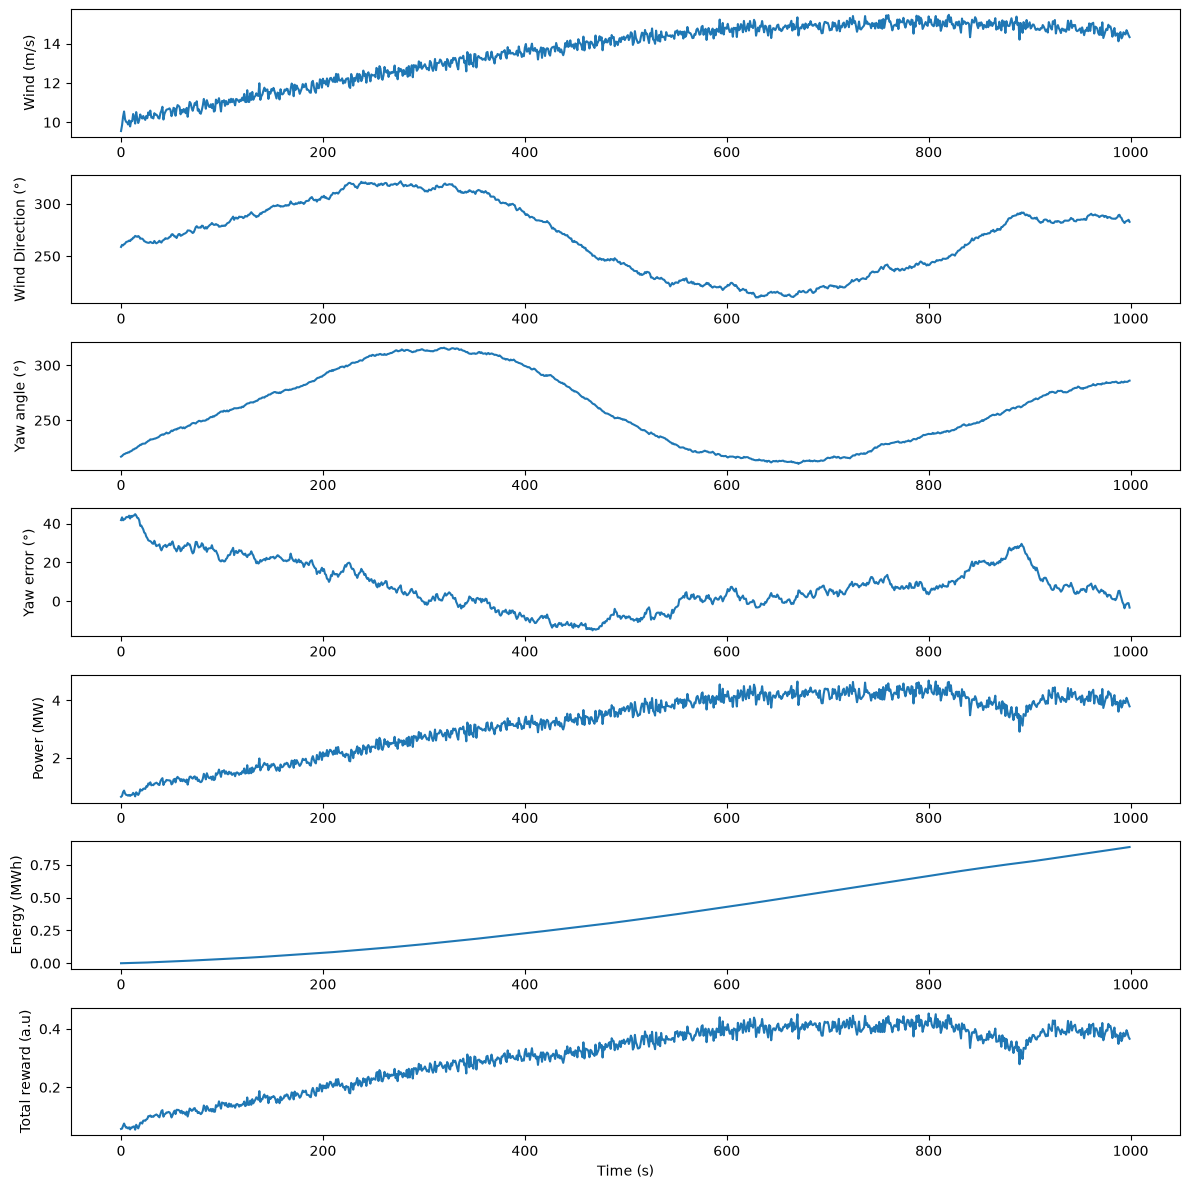

In [16]:
time=np.arange(len(speed))

plt.figure(figsize=(12,12))


plt.subplot(7,1,1)
plt.plot(time,speed)
plt.ylabel("Wind (m/s)")


plt.subplot(7,1,2)
plt.plot(time,direction)
plt.ylabel(r"Wind Direction ($\degree$)")


plt.subplot(7,1,3)
plt.plot(time,yaw)
plt.ylabel(r"Yaw angle ($\degree$)")


plt.subplot(7,1,4)
plt.plot(time,error)
plt.ylabel(r"Yaw error ($\degree$)")


plt.subplot(7,1,5)
plt.plot(time,power)
plt.ylabel("Power (MW)")


plt.subplot(7,1,6)
plt.plot(time,energy)
plt.ylabel("Energy (MWh)")

plt.subplot(7,1,7)
plt.plot(time,total_reward)
plt.ylabel("Total reward (a.u)")

plt.xlabel("Time (s)")


plt.tight_layout()

plt.show()

# Comparing Results

Loaded Baseline: 1000 rows from baseline_results.csv
Loaded Modified reward A - 1 0.5 0.02  : 1000 rows from rewardChange_results_1_05_002.csv
Loaded Modified reward B - 1 0.1 0.005 : 1000 rows from rewardChange_results_1_01_0005.csv
Loaded Modified reward C - 1 0.5 0.1   : 1000 rows from rewardChange_results_1_05_01.csv
Loaded Modified reward D - 1 0.5 0     : 1000 rows from rewardChange_results_1_05_0.csv
Loaded Modified reward E - 1 0.5 0.5   : 1000 rows from rewardChange_results_1_05_05.csv
Loaded Modified reward Aw - 1 0.5 0.02 : 1000 rows from rewardChange_results_1_05_002.csv
Loaded Modified reward Bw - 1 0.1 0.005: 1000 rows from rewardChange_results_1_01_0005.csv


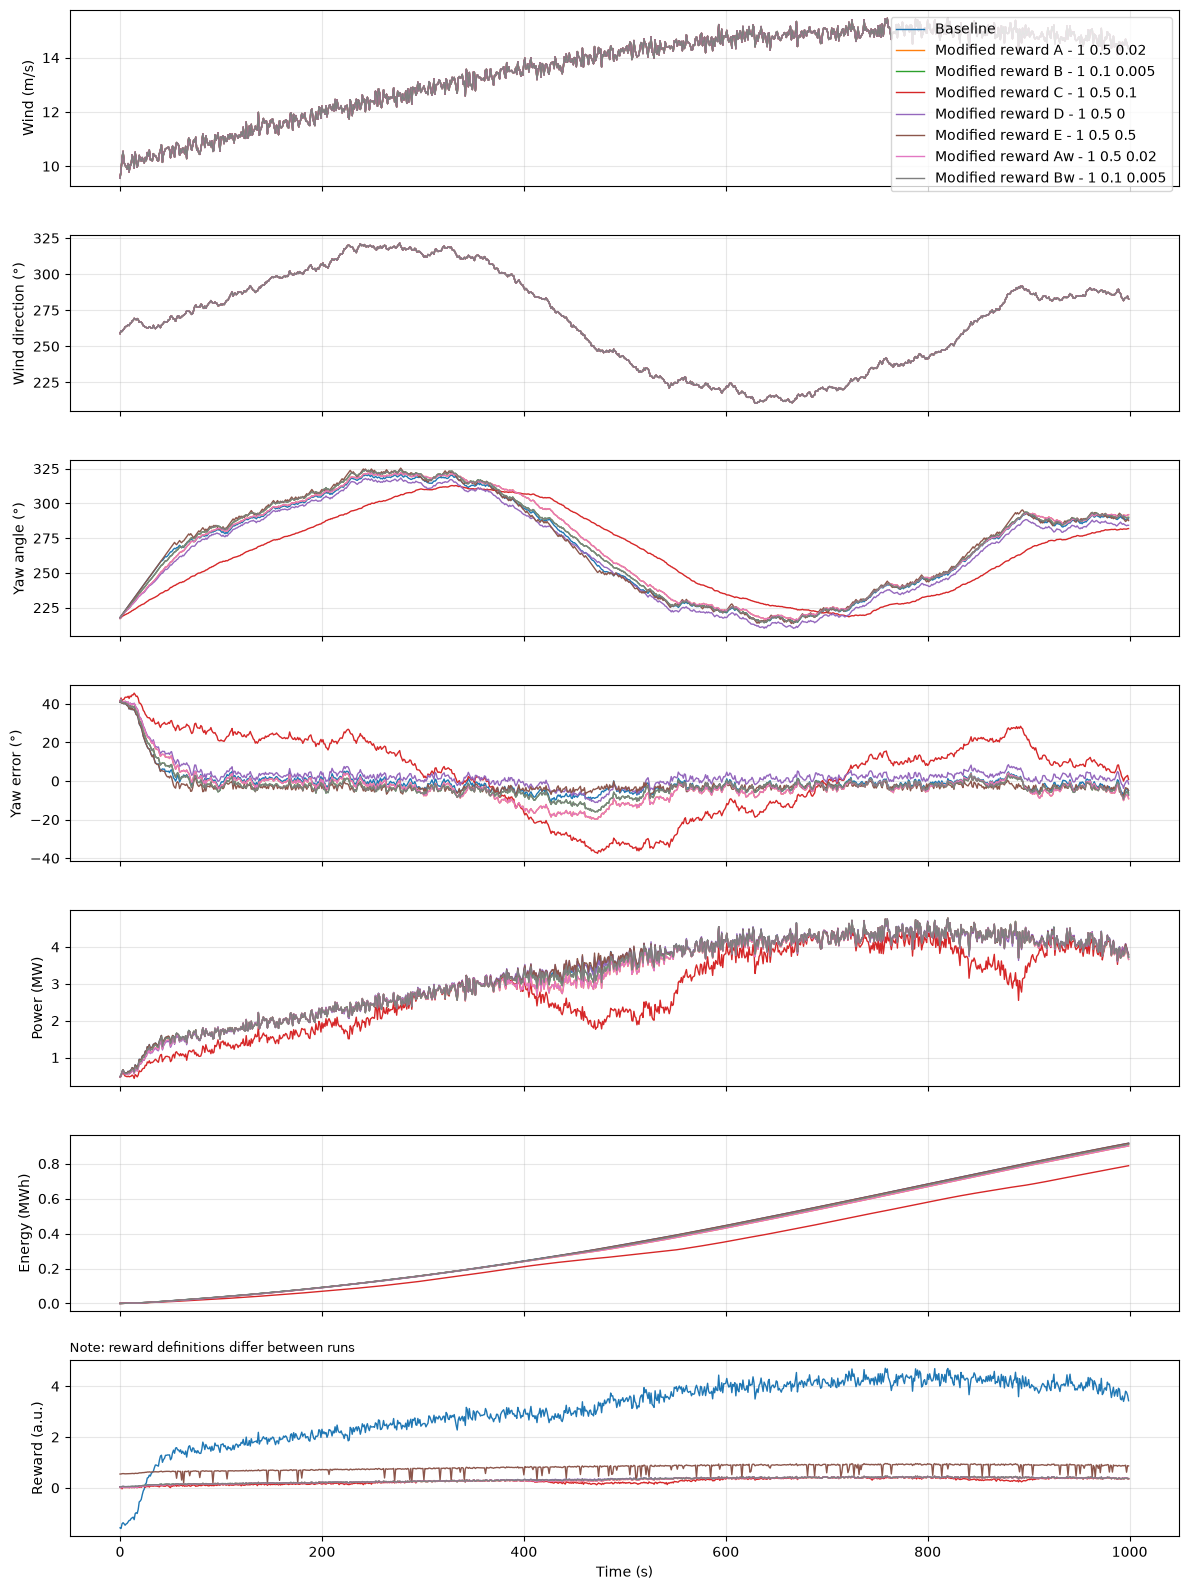

,Total energy (MWh),Mean |yaw error| (deg),Mean |yaw error| steady state (deg)
Run,,,
Baseline,0.917,3.749,2.977
Modified reward A - 1 0.5 0.02,0.902,6.102,5.544
Modified reward B - 1 0.1 0.005,0.911,5.067,4.311
Modified reward C - 1 0.5 0.1,0.788,17.904,15.590
Modified reward D - 1 0.5 0,0.915,4.221,2.734
Modified reward E - 1 0.5 0.5,0.917,4.226,3.340
Modified reward Aw - 1 0.5 0.02,0.902,6.102,5.544
Modified reward Bw - 1 0.1 0.005,0.911,5.067,4.311


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# Constants
# ---------------------------------------------------------------
# Map: label shown in the legend -> path to CSV file
CSV_FILES_TO_COMPARE = {
    "Baseline": "baseline_results.csv",
    "Modified reward A - 1 0.5 0.02  ": "rewardChange_results_1_05_002.csv",
    "Modified reward B - 1 0.1 0.005 ": "rewardChange_results_1_01_0005.csv",
    "Modified reward C - 1 0.5 0.1   ": "rewardChange_results_1_05_01.csv",
    "Modified reward D - 1 0.5 0     ": "rewardChange_results_1_05_0.csv",
    "Modified reward E - 1 0.5 0.5   ": "rewardChange_results_1_05_05.csv",
    "Modified reward Aw - 1 0.5 0.02 ": "rewardChange_results_1_05_002.csv",
    "Modified reward Bw - 1 0.1 0.005": "rewardChange_results_1_01_0005.csv",
    #"Modified reward Cw - 1 0.5 0.1  ": "rewardChange_results_1_05_01.csv",
    #"Modified reward Dw - 1 0.5 0    ": "rewardChange_results_1_05_0.csv",
    #"Modified reward Ew - 1 0.5 0.5  ": "rewardChange_results_1_05_05.csv"

}

TIME_STEP_S = 1.0               # dt in the environment
STEADY_STATE_START_TIME_S = 200 # ignore initial alignment transient in steady-state KPIs
FIGURE_SIZE = (12, 16)
SAVE_FIGURE_FILENAME = "comparison_plot.png"   # set to None to skip saving

# Columns to plot: (column name in CSV, y-axis label)
COLUMNS_TO_PLOT = [
    ("wind_speed_m_per_s",             "Wind (m/s)"),
    ("wind_direction_deg",             r"Wind direction ($\degree$)"),
    ("yaw_angle_deg",                  r"Yaw angle ($\degree$)"),
    ("yaw_error_deg",                  r"Yaw error ($\degree$)"),
    ("power_MW",                       "Power (MW)"),
    ("cumulative_energy_MWh",          "Energy (MWh)"),
    ("reward",                         "Reward (a.u.)"),
]

# ---------------------------------------------------------------
# Load all result files
# ---------------------------------------------------------------
loaded_results = {}
for run_label, csv_path in CSV_FILES_TO_COMPARE.items():
    loaded_results[run_label] = pd.read_csv(csv_path)
    print(f"Loaded {run_label}: {len(loaded_results[run_label])} rows from {csv_path}")

# ---------------------------------------------------------------
# Time series comparison plot
# ---------------------------------------------------------------
figure, axes = plt.subplots(len(COLUMNS_TO_PLOT), 1, figsize=FIGURE_SIZE, sharex=True)

for axis, (column_name, y_label) in zip(axes, COLUMNS_TO_PLOT):
    for run_label, results_table in loaded_results.items():
        # Skip gracefully if an older CSV is missing a column
        if column_name not in results_table.columns:
            continue
        axis.plot(results_table["time_s"], results_table[column_name],
                  label=run_label, linewidth=1.0)
    axis.set_ylabel(y_label)
    axis.grid(alpha=0.3)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
# Reward functions differ between runs, so the reward values are not directly comparable
axes[-1].set_title("Note: reward definitions differ between runs", fontsize=9, loc="left")

plt.tight_layout()
if SAVE_FIGURE_FILENAME is not None:
    plt.savefig(SAVE_FIGURE_FILENAME, dpi=200)
plt.show()

# ---------------------------------------------------------------
# KPI summary table
# ---------------------------------------------------------------
kpi_rows = []
for run_label, results_table in loaded_results.items():
    absolute_yaw_error = results_table["yaw_error_deg"].abs()
    steady_state_mask = results_table["time_s"] >= STEADY_STATE_START_TIME_S

    kpis = {
        "Run": run_label,
        "Total energy (MWh)": results_table["cumulative_energy_MWh"].iloc[-1],
        "Mean |yaw error| (deg)": absolute_yaw_error.mean(),
        "Mean |yaw error| steady state (deg)": absolute_yaw_error[steady_state_mask].mean(),
    }

    if "yaw_velocity_command_deg_per_s" in results_table.columns:
        yaw_rate = results_table["yaw_velocity_command_deg_per_s"].to_numpy()
        yaw_direction_sign = np.sign(yaw_rate)
        kpis["Total yaw travel (deg)"] = np.sum(np.abs(yaw_rate)) * TIME_STEP_S
        kpis["Direction reversals"] = int(np.sum(yaw_direction_sign[1:] * yaw_direction_sign[:-1] < 0))

    kpi_rows.append(kpis)

kpi_table = pd.DataFrame(kpi_rows).set_index("Run")
display(kpi_table.round(3))